# Regressionsbaum 

In [ ]:
import pandas as pd
from matplotlib import pyplot as plt
from sklearn import tree

from vnw.defines.defines import (
    TESTSET_PATH,
    TRAINSET_PATH,
    VALSET_PATH,
)
from vnw.load_data.load_prepare_data import LoadPrepareData
from vnw.load_data.set_loader import SetLoader
from vnw.ml.dataset_loader import TrainTestValSplitter
from vnw.ml.feature_engineer import FeatureEngineer

In [5]:
df_raw = LoadPrepareData().load_and_prepare_data()

df = df_raw[
    [
        "Category",
        "Subcategory",
        "ProductLine",
        "Model",
        "OrderQuantity",
    ]
].copy()

df_agg = df.groupby(
    ["Category", "Subcategory", "ProductLine", "Model"], as_index=False
).agg({"OrderQuantity": "sum"})
df_agg

,Category,Subcategory,ProductLine,Model,OrderQuantity
0,Accessories,Bike Racks,S,Hitch Rack - 4-Bike,328
1,Accessories,Bike Stands,M,All-Purpose Bike Stand,249
2,Accessories,Bottles and Cages,M,Mountain Bottle Cage,2025
3,Accessories,Bottles and Cages,R,Road Bottle Cage,1712
4,Accessories,Bottles and Cages,S,Water Bottle,4244
5,Accessories,Cleaners,S,Bike Wash,908
6,Accessories,Fenders,M,Fender Set - Mountain,2121
7,Accessories,Helmets,S,Sport-100,6440
8,Accessories,Hydration Packs,S,Hydration Pack,733
9,Accessories,Tires and Tubes,M,HL Mountain Tire,1396


In [7]:
TrainTestValSplitter(df_agg).get_splits_save_as_parquet()
set_loader = SetLoader(TRAINSET_PATH, TESTSET_PATH, VALSET_PATH)
trainset, testset, valset = set_loader.load_sets()

Trainset: (28, 5)
Testset: (6, 5)
Valset: (6, 5)


In [8]:
FEATURES = [
    "Category",
    "Subcategory",
    "ProductLine",
    "Model",
]

TARGET = "OrderQuantity"


X_train = trainset[FEATURES]
y_train = trainset[TARGET]

X_val = valset[FEATURES]
y_val = valset[TARGET]

X_test = testset[FEATURES]
y_test = testset[TARGET]


feature_engineer = FeatureEngineer(FEATURES)

X_train_enc = feature_engineer.fit_transform(X_train)
X_val_enc = feature_engineer.transform(X_val)
X_test_enc = feature_engineer.transform(X_test)

print("Encoded Train:", X_train_enc.shape)
print("Encoded Val:", X_val_enc.shape)
print("Encoded Test:", X_test_enc.shape)

Encoded Train: (28, 51)
Encoded Val: (6, 51)
Encoded Test: (6, 51)


In [9]:
from vnw.ml.dt_model import DecisionTreeModel
from vnw.ml.gb_model import GradientBoostingModel
from vnw.ml.rf_model import RandomForestModel

models = {
    "Decision Tree": DecisionTreeModel(),
    "Random Forest": RandomForestModel(),
    "Gradient Boosting": GradientBoostingModel(),
}

results = {}

for name, model in models.items():
    print(f"\n--- {name} ---")

    model.fit(X_train_enc, y_train)

    val_metrics = model.evaluate(X_val_enc, y_val)

    results[name] = {
        "model": model,
        **val_metrics,
    }

# Modelle anhand der Validation-Ergebnisse vergleichen
comparison = pd.DataFrame(
    {
        name: {
            "MAE": result["MAE"],
            "RMSE": result["RMSE"],
            "R2": result["R2"],
        }
        for name, result in results.items()
    }
).T.sort_values("MAE")

print("\nValidation-Vergleich:")
print(comparison)

# Bestes Modell anhand des Validation-MAE auswählen
best_name = comparison["MAE"].idxmin()
best_model = results[best_name]["model"]

print("\nBestes Modell:", best_name)

# Finale Test-Evaluation: erst nach der Modellauswahl
test_metrics = best_model.evaluate(X_test_enc, y_test)

print("\nFinale Test-Ergebnisse:")
print(test_metrics)


--- Decision Tree ---
Beste Parameter: {'ccp_alpha': 0.0, 'max_depth': 3, 'min_samples_leaf': 10}
Beste CV-MAE: 904.6750353028614

--- Random Forest ---
Beste Parameter: {'max_depth': 3, 'max_features': 0.7, 'min_samples_leaf': 10, 'n_estimators': 300}
Beste CV-MAE: 838.5522532279314

--- Gradient Boosting ---
Beste Parameter: {'learning_rate': 0.03, 'max_depth': 3, 'min_samples_leaf': 5, 'n_estimators': 100, 'subsample': 1.0}
Beste CV-MAE: 907.0827200749242

Validation-Vergleich:
                          MAE        RMSE        R2
Decision Tree      562.899306  619.818785 -0.340838
Random Forest      566.214440  655.380841 -0.499112
Gradient Boosting  595.102653  678.127331 -0.604979

Bestes Modell: Decision Tree

Finale Test-Ergebnisse:
{'MAE': 1003.3715277777778, 'RMSE': 1288.6664691031797, 'R2': -0.1384740754699485}


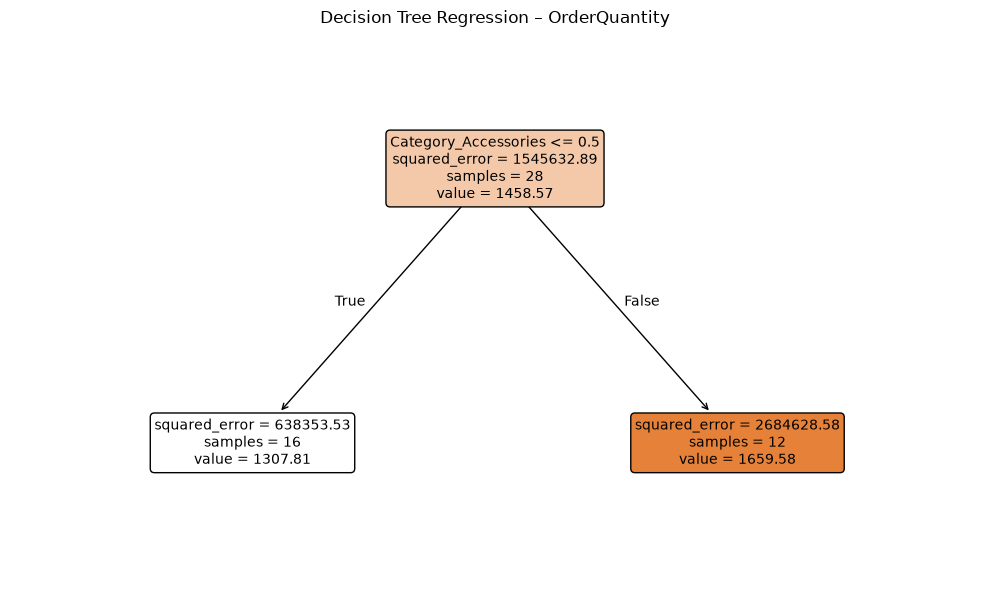

In [ ]:
tree_model = best_model.best_model

fig = plt.figure(figsize=(10, 6))

_ = tree.plot_tree(
    tree_model,
    feature_names=X_train_enc.columns.tolist(),
    filled=True,
    rounded=True,
    precision=2,
    fontsize=10,
)

plt.title("Decision Tree Regression – OrderQuantity")
plt.tight_layout()
plt.show()

In [11]:
tree_model = best_model.best_model

print("Baumtiefe:", tree_model.get_depth())
print("Anzahl Blätter:", tree_model.get_n_leaves())
print("Pruning-Parameter:", tree_model.ccp_alpha)

Baumtiefe: 1
Anzahl Blätter: 2
Pruning-Parameter: 0.0


# Predictions

In [12]:
new_product = pd.DataFrame(
    [
        {
            "Category": "Bikes",
            "Subcategory": "Road Bikes",
            "ProductLine": "Road",
            "Model": "Road-150",
        }
    ]
)
new_product_enc = feature_engineer.transform(new_product)
prediction = best_model.predict(new_product_enc)[0]

print("Neues Produkt: Road-Racer")
print("Gewähltes Modell:", best_name)
print(f"Prognostizierte Bestellmenge: {prediction:.2f}")
print("Gerundete Prognose:", max(0, round(prediction)))

Neues Produkt: Road-Racer
Gewähltes Modell: Decision Tree
Prognostizierte Bestellmenge: 1307.81
Gerundete Prognose: 1308


                          Feature  Importance
0            Category_Accessories         1.0
1                  Category_Bikes         0.0
2               Category_Clothing         0.0
3          Subcategory_Bike Racks         0.0
4         Subcategory_Bike Stands         0.0
5   Subcategory_Bottles and Cages         0.0
6                Subcategory_Caps         0.0
7            Subcategory_Cleaners         0.0
8             Subcategory_Fenders         0.0
9             Subcategory_Helmets         0.0
10    Subcategory_Hydration Packs         0.0
11            Subcategory_Jerseys         0.0
12     Subcategory_Mountain Bikes         0.0
13         Subcategory_Road Bikes         0.0
14             Subcategory_Shorts         0.0
15              Subcategory_Socks         0.0
16    Subcategory_Tires and Tubes         0.0
17      Subcategory_Touring Bikes         0.0
18              Subcategory_Vests         0.0
19                  ProductLine_M         0.0


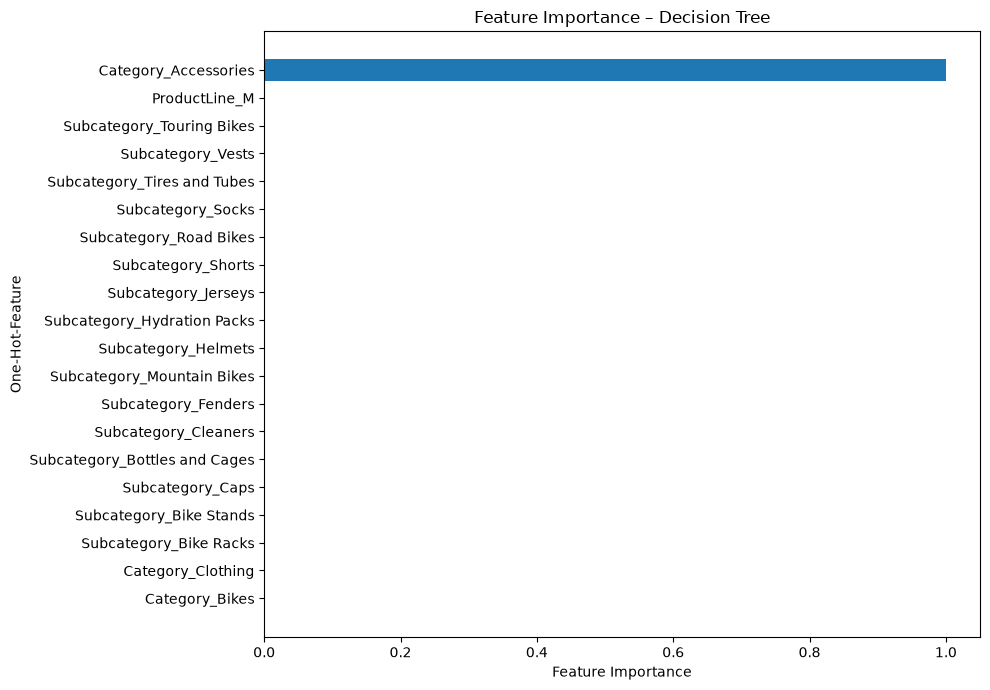

In [13]:
import matplotlib.pyplot as plt
import pandas as pd

# Feature Importance des ausgewählten Modells
importance = pd.DataFrame(
    {
        "Feature": X_train_enc.columns,
        "Importance": best_model.best_model.feature_importances_,
    }
).sort_values("Importance", ascending=False)

print(importance.head(20))

# Visualisierung
top_features = importance.head(20).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("One-Hot-Feature")
plt.title(f"Feature Importance – {best_name}")
plt.tight_layout()
plt.show()

In [14]:
importance["OriginalFeature"] = importance["Feature"].str.split("_").str[0]

grouped_importance = (
    importance.groupby("OriginalFeature")["Importance"]
    .sum()
    .sort_values(ascending=False)
)

print("\nAggregierte Feature Importance:")
print(grouped_importance)


Aggregierte Feature Importance:
OriginalFeature
Category       1.0
Model          0.0
ProductLine    0.0
Subcategory    0.0
Name: Importance, dtype: float64
